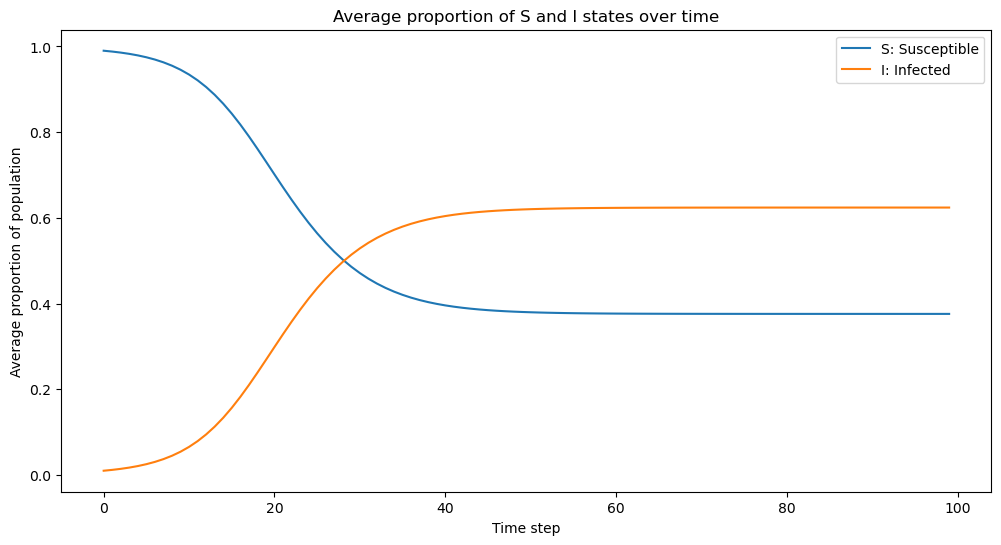

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 参数设置
N = 10  # 节点数量
P = 1000  # 总人口
n = np.random.randint(50, 150, size=N)  # 每个节点的初始人口
n = n / np.sum(n) * P  # 调整总人口数量
beta = 0.003  # 感染率
mu = 0.1  # 恢复率
p = 0.1  # 移动概率
steps = 100  # 时间步数

# 初始化节点状态
rho = np.full(N, 0.01)  # 初始感染率
adj_matrix = np.random.rand(N, N)  # 随机生成邻接矩阵
np.fill_diagonal(adj_matrix, 0)  # 对角线元素为0
W = adj_matrix / np.sum(adj_matrix, axis=1, keepdims=True)  # 归一化邻接矩阵

# 记录结果
rho_history = np.zeros((steps, N))  # 生成一个形状为 (steps, N) 的二维数组（矩阵）
S_history = np.zeros(steps)
I_history = np.zeros(steps)


def get_n_j_to_i(n, p, W):
    """
    计算从节点j移动到节点i的人数矩阵
    """
    N = len(n)
    n_j_to_i = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                n_j_to_i[j, i] = (1 - p) * n[i]
            else:
                n_j_to_i[j, i] = p * W[j, i] * n[j]
    return n_j_to_i


def Pi(t, rho, n, n_j_to_i):
    """
    计算每个节点感染的概率
    """
    P_i = np.zeros(N)
    for i in range(N):
        product = 1
        for j in range(N):
            product *= (1 - beta * rho[j]) ** n_j_to_i[j, i]
        P_i[i] = 1 - product
    return P_i


def Pi_effective(t, rho, n, W, p, n_j_to_i):
    """
    计算每个节点实际的感染概率
    """
    P_effective = np.zeros(N)
    P_i = Pi(t, rho, n, n_j_to_i)
    for i in range(N):
        term1 = (1 - p) * P_i[i]
        term2 = p * np.sum([W[i, j] * P_i[j] for j in range(N)])
        P_effective[i] = term1 + term2
    return P_effective


# 模拟过程
for t in range(steps):
    rho_history[t] = rho
    S_history[t] = np.mean(1 - rho)  # 计算易感者的平均比例
    I_history[t] = np.mean(rho)  # 计算感染者的平均比例
    n_j_to_i = get_n_j_to_i(n, p, W)
    P_effective = Pi_effective(t, rho, n, W, p, n_j_to_i)
    new_rho = (1 - mu) * rho + (1 - rho) * P_effective
    # print(new_rho)
    rho = new_rho

# 结果可视化
plt.figure(figsize=(12, 6))
plt.plot(S_history, label="S: Susceptible")
plt.plot(I_history, label="I: Infected")
plt.xlabel("Time step")
plt.ylabel("Average proportion of population")
plt.title("Average proportion of S and I states over time")
plt.legend()
plt.show()


第0步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第1步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第2步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第3步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第4步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第5步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第6步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 79.2         8.66172097]
 [19.8584054   0.1415946  79.2       ]]
第7步的n_j_to_i:
 [[79.2         7.87849662 12.12150338]
 [11.33827903 7

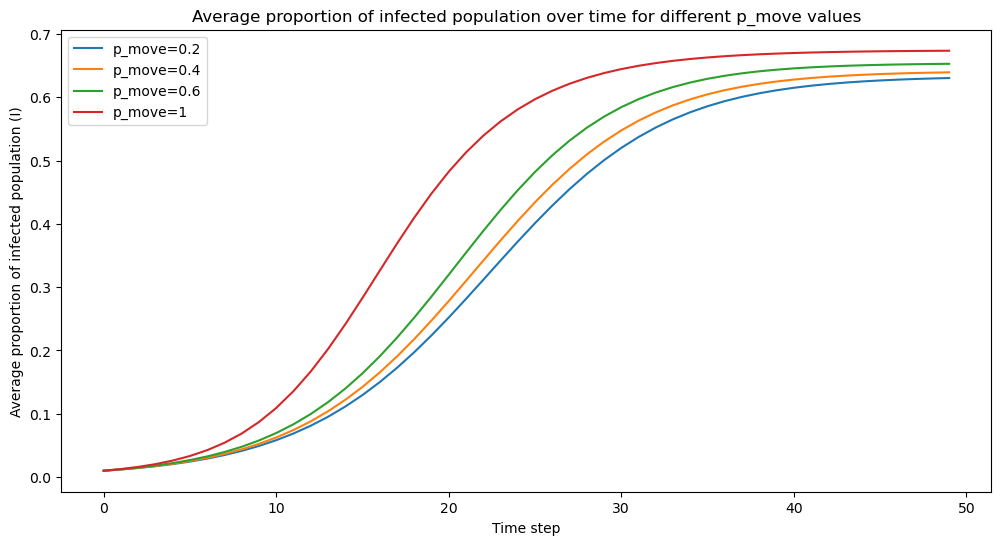

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 参数设置
N = 3  # 节点数量
n = np.full(N,100)  # 每个节点的初始人口
beta = 0.003  # 感染率
mu = 0.1  # 恢复率
steps = 50  # 时间步数

# 初始化节点状态
rho = np.full(N, 0.01)  # 初始感染率
adj_matrix = np.random.rand(N, N)  # 随机生成邻接矩阵
np.fill_diagonal(adj_matrix, 0)  # 对角线元素为0
W = adj_matrix / np.sum(adj_matrix, axis=1, keepdims=True)  # 归一化邻接矩阵

# 定义计算从节点j移动到节点i的人数矩阵
def get_n_j_to_i(n, p, W):
    N = len(n)
    n_j_to_i = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                n_j_to_i[j, i] = (1 - p) * n[i] * 0.99
            else:
                n_j_to_i[j, i] = p * W[j, i] * n[j]
    return n_j_to_i

# 定义计算每个节点感染的概率
def Pi(t, rho, n, n_j_to_i):
    N = len(n)
    P_i = np.zeros(N)
    for i in range(N):
        product = 1
        for j in range(N):
            product *= (1 - beta * rho[j]) ** n_j_to_i[j, i]
        P_i[i] = 1 - product
    return P_i

# 定义计算每个节点实际的感染概率
def Pi_effective(t, rho, n, W, p, n_j_to_i):
    N = len(n)
    P_effective = np.zeros(N)
    P_i = Pi(t, rho, n, n_j_to_i)
    for i in range(N):
        term1 = (1 - p) * P_i[i]
        term2 = p * np.sum([W[i, j] * P_i[j] for j in range(N)])
        P_effective[i] = term1 + term2
        # print("term1:",P_i[i])
        # print("term2:",np.sum([W[i, j] * P_i[j] for j in range(N)]))
    return P_effective

# 模拟过程
def run_simulation(p):
    rho = np.full(N, 0.01)  # 重置初始感染率
    I_history = np.zeros(steps)
    S_history = np.zeros(steps)
    for t in range(steps):
        I_history[t] = np.mean(rho)  # 计算感染者的平均比例
        S_history[t] = np.mean(1 - rho)  # 计算易感者的平均比例
        n_j_to_i = get_n_j_to_i(n, p, W)
        # print(f"第{t}步的n_j_to_i:\n", n_j_to_i)
        P_effective = Pi_effective(t, rho, n, W, p, n_j_to_i)
        new_rho = (1 - mu) * rho + (1 - rho) * P_effective
        rho = new_rho
    return I_history

# 不同的移动概率值
p_values = [0.2, 0.4, 0.6, 1]

# 记录不同p值下的结果
results = {}

for p in p_values:
    results[p] = run_simulation(p)

# 结果可视化
plt.figure(figsize=(12, 6))
for p, I_history in results.items():
    plt.plot(I_history, label=f'p_move={p}')
plt.xlabel("Time step")
plt.ylabel("Average proportion of infected population (I)")
plt.title("Average proportion of infected population over time for different p_move values")
plt.legend()
plt.show()


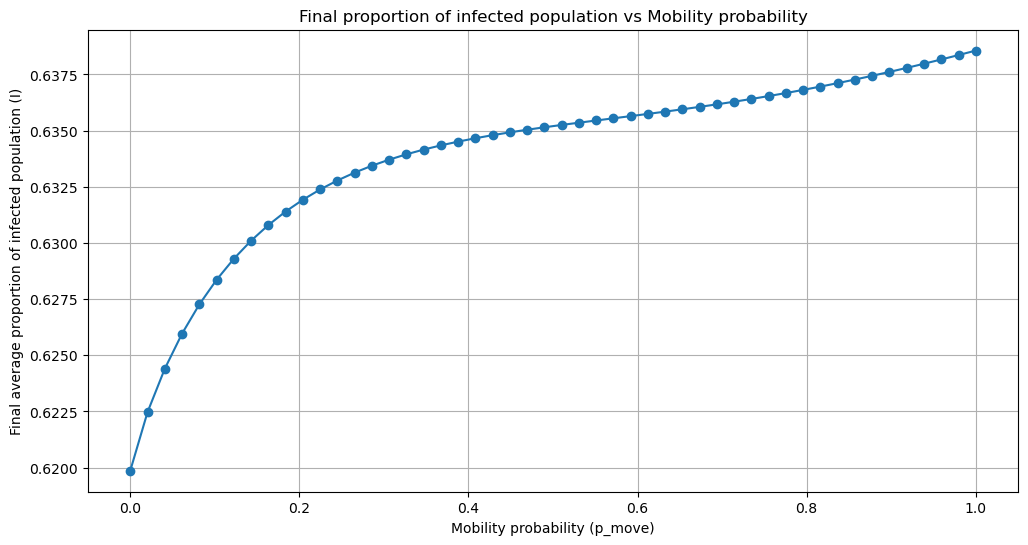

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 参数设置
N = 10  # 节点数量
P = 1000  # 总人口
n = np.random.randint(50, 150, size=N)  # 每个节点的初始人口
n = n / np.sum(n) * P  # 调整总人口数量
beta = 0.003  # 感染率
mu = 0.1  # 恢复率
steps = 100  # 时间步数

# 初始化节点状态
rho = np.full(N, 0.01)  # 初始感染率
adj_matrix = np.random.rand(N, N)  # 随机生成邻接矩阵
np.fill_diagonal(adj_matrix, 0)  # 对角线元素为0
W = adj_matrix / np.sum(adj_matrix, axis=1, keepdims=True)  # 归一化邻接矩阵

# 定义计算从节点j移动到节点i的人数矩阵
def get_n_j_to_i(n, p, W):
    N = len(n)
    n_j_to_i = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                n_j_to_i[j, i] = (1 - p) * n[i]
            else:
                n_j_to_i[j, i] = p * W[j, i] * n[j]
    return n_j_to_i

# 定义计算每个节点感染的概率
def Pi(t, rho, n, n_j_to_i):
    N = len(n)
    P_i = np.zeros(N)
    for i in range(N):
        product = 1
        for j in range(N):
            product *= (1 - beta * rho[j]) ** n_j_to_i[j, i]
        P_i[i] = 1 - product
    return P_i

# 定义计算每个节点实际的感染概率
def Pi_effective(t, rho, n, W, p, n_j_to_i):
    N = len(n)
    P_effective = np.zeros(N)
    P_i = Pi(t, rho, n, n_j_to_i)
    for i in range(N):
        term1 = (1 - p) * P_i[i]
        term2 = p * np.sum([W[i, j] * P_i[j] for j in range(N)])
        P_effective[i] = term1 + term2
    return P_effective

# 模拟过程
def run_simulation(p):
    rho = np.full(N, 0.01)  # 重置初始感染率
    for t in range(steps):
        n_j_to_i = get_n_j_to_i(n, p, W)
        P_effective = Pi_effective(t, rho, n, W, p, n_j_to_i)
        new_rho = (1 - mu) * rho + (1 - rho) * P_effective
        rho = new_rho
    return np.mean(rho)

# 不同的移动概率值
p_values = np.linspace(0, 1, 50)  # 生成从0到1的50个均匀间隔的p值

# 记录不同p值下的最终感染比例
final_infection_ratios = [run_simulation(p) for p in p_values]

# 结果可视化
plt.figure(figsize=(12, 6))
plt.plot(p_values, final_infection_ratios, marker='o')
plt.xlabel("Mobility probability (p_move)")
plt.ylabel("Final average proportion of infected population (I)")
plt.title("Final proportion of infected population vs Mobility probability")
plt.grid(True)
plt.show()


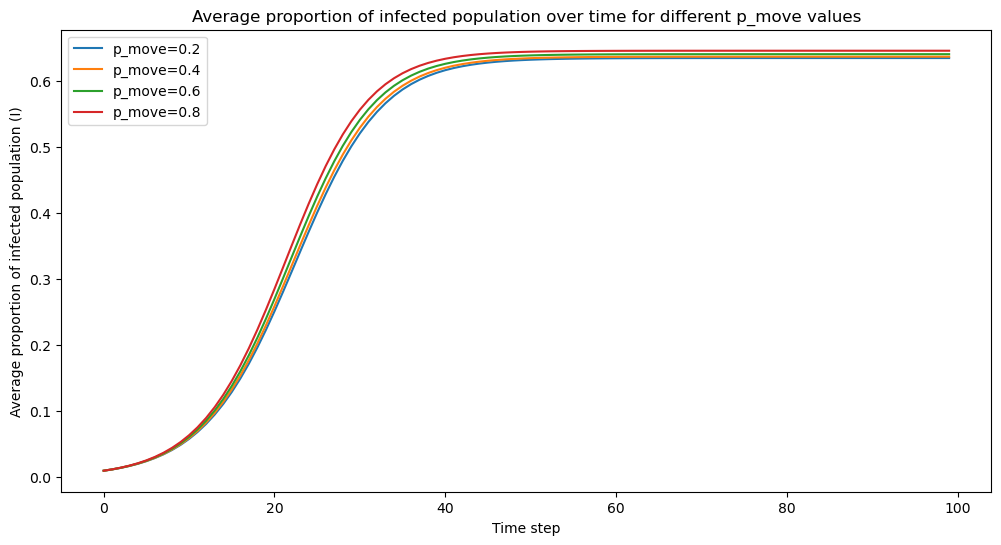

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 参数设置
N = 10  # 节点数量
n = np.full(N, 100)  # 每个节点的初始人口
beta = 0.003  # 感染率
mu = 0.1  # 恢复率
steps = 100  # 时间步数

# 初始化节点状态
rho_init = np.full(N, 0.01)  # 初始感染率
adj_matrix = np.random.rand(N, N)  # 随机生成邻接矩阵
np.fill_diagonal(adj_matrix, 0)  # 对角线元素为0
W = adj_matrix / np.sum(adj_matrix, axis=1, keepdims=True)  # 归一化邻接矩阵

# 定义计算从节点j移动到节点i的人数矩阵
def get_n_j_to_i(n, p, W):
    N = len(n)
    n_j_to_i = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                n_j_to_i[j, i] = (1 - p) * n[i]
            else:
                n_j_to_i[j, i] = p * W[j, i] * n[j]
    return n_j_to_i

# 定义计算每个节点感染的概率
def Pi(t, rho, n, n_j_to_i):
    N = len(n)
    P_i = np.zeros(N)
    for i in range(N):
        product = 1
        for j in range(N):
            product *= (1 - beta * rho[j]) ** n_j_to_i[j, i]
        P_i[i] = 1 - product
    return P_i

# 定义计算每个节点实际的感染概率
def Pi_effective(t, rho, n, W, p, n_j_to_i):
    N = len(n)
    P_effective = np.zeros(N)
    P_i = Pi(t, rho, n, n_j_to_i)
    for i in range(N):
        term1 = (1 - p) * P_i[i]
        term2 = p * np.sum([W[i, j] * P_i[j] for j in range(N)])
        P_effective[i] = term1 + term2
    return P_effective

# 模拟过程
def run_simulation(p):
    rho = np.full(N, 0.01)  # 重置初始感染率
    I_history = np.zeros(steps)
    S_history = np.zeros(steps)

    # 初始化存储变量
    results = {
        "time_step": [],
        "p_move": [],
        "n_j_to_i": [],
        "Pi": [],
        "P_effective": [],
        "new_rho": [],
        "rho": [],
        "I_history": [],
        "S_history": []
    }

    for t in range(steps):
        I_history[t] = np.mean(rho)  # 计算感染者的平均比例
        S_history[t] = np.mean(1 - rho)  # 计算易感者的平均比例
        n_j_to_i = get_n_j_to_i(n, p, W)
        P_effective = Pi_effective(t, rho, n, W, p, n_j_to_i)
        new_rho = (1 - mu) * rho + (1 - rho) * P_effective

        # 记录变量
        results["time_step"].append(t)
        results["p_move"].append(p)
        results["n_j_to_i"].append(n_j_to_i.flatten())
        results["Pi"].append(Pi(t, rho, n, n_j_to_i))
        results["P_effective"].append(P_effective)
        results["new_rho"].append(new_rho)
        results["rho"].append(rho)
        results["I_history"].append(I_history[t])
        results["S_history"].append(S_history[t])

        rho = new_rho

    return results

# 不同的移动概率值
p_values = [0.2, 0.4, 0.6, 0.8]

# 记录所有p值下的结果
all_results = []

for p in p_values:
    result = run_simulation(p)
    all_results.append(pd.DataFrame(result))

# 合并所有结果到一个DataFrame
final_results = pd.concat(all_results)

# 保存到CSV文件
final_results.to_csv('simulation_results.csv', index=False)

# 可视化结果
plt.figure(figsize=(12, 6))
for p in p_values:
    plt.plot(final_results[final_results["p_move"] == p]["I_history"], label=f'p_move={p}')
plt.xlabel("Time step")
plt.ylabel("Average proportion of infected population (I)")
plt.title("Average proportion of infected population over time for different p_move values")
plt.legend()
plt.show()
